# Forced alignment with the Montreal Forced Aligner

In [2]:
import os
import tqdm
import glob
import librosa
import subprocess
import parselmouth
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from IPython.display import Audio
from parselmouth.praat import call
from src.psola import AudioModifier

In [3]:
prepare_data_dir = './output/problem2/data'
os.makedirs(prepare_data_dir, exist_ok=True)

my_voice_path = os.path.join(prepare_data_dir, 'my_voice.wav')
audio_modifier = AudioModifier(my_voice_path)
slower_audio = audio_modifier.apply_effect(("duration", 1.5))
slower_audio_path = os.path.join(prepare_data_dir, 'my_voice_slower.wav')
slower_audio.save(slower_audio_path, "WAV")

In [4]:
# Prepare transcript
my_voice_transcript = "When the sunlight strikes raindrops in the air, they act as a prism and form a rainbow. The rainbow is a division of white light into many beautiful colors. These take the shape of a long round arch, with its path high above, and its two ends apparently beyond the horizon."
clean_lj_transcript = "For although the Chinese took impressions from wood blocks engraved in relief for centuries before the woodcutters of the Netherlands, by a similar process"
clean_jfk_transcript = "And so, my fellow Americans, ask not what your country can do for you, ask what you can do for your country."

for transcript_path in [os.path.join(prepare_data_dir, 'my_voice.lab'), os.path.join(prepare_data_dir, 'my_voice_noisy.lab'), os.path.join(prepare_data_dir, 'my_voice_slower.lab')]:
    with open(transcript_path, 'w') as f:
        f.write(my_voice_transcript)

out_clean_lj_transcript = os.path.join(prepare_data_dir, 'clean_lj.lab')
with open(out_clean_lj_transcript, 'w') as f:
    f.write(clean_lj_transcript)

out_clean_jfk_transcript = os.path.join(prepare_data_dir, 'clean_jfk.lab')

with open(out_clean_jfk_transcript, 'w') as f:
    f.write(clean_jfk_transcript)
    

In [5]:
wav_files = glob.glob(os.path.join(prepare_data_dir, '*.wav'))  
textgrid_dir = os.path.join(os.path.dirname(prepare_data_dir), 'TextGrids')
all_exists = all(os.path.exists(os.path.join(textgrid_dir, os.path.basename(wav_file).replace('.wav', '.TextGrid'))) for wav_file in wav_files)

if all_exists:
    print("All TextGrids already exist.")
else:
    print("Generating TextGrids...")
    cmd = [
        "mfa", "align",
        "--clean",
        "--single_speaker",
        prepare_data_dir,
        "english_us_arpa",
        "english_us_arpa",
        f"{os.path.join(os.path.dirname(prepare_data_dir), 'TextGrids')}"
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

    print(result.stdout)
    print(result.stderr)
    print("Return code:", result.returncode)

All TextGrids already exist.


## Problem 2(a): Align and inspect

In [6]:
textgrid_dir = './output/problem2/TextGrids'
textgrid_paths = sorted(glob.glob(f'{textgrid_dir}/*.TextGrid'))

In [7]:
table = []
for utterance in textgrid_paths:  # Assuming 'utterances' is a list of utterance identifiers
    tg = parselmouth.read(utterance)
    words = []
    unk_words = []
    phones = []
    unk_phones = []
    unknown_label = ["<unk>", "spn"]
    first_word_t = None
    last_word_t = None
    for tier in range(1, 3):  # Assuming tier 1 is words and tier 2 is phones
        num_intervals = call(tg, "Get number of intervals", tier)
        for i in range(1, num_intervals + 1):
            label = call(tg, "Get label of interval", tier, i)
            if label != "" and tier == 1:
                words.append(label)
                if label in unknown_label:
                    unk_words.append(label)
                if first_word_t is None:
                    first_word_t = call(tg, "Get start time of interval", tier, i)
                last_word_t = call(tg, "Get end time of interval", tier, i)

            elif label != "" and tier == 2:
                phones.append(label)
                if label in unknown_label:
                    unk_phones.append(label)

    table.append({
        "utterance": os.path.basename(utterance).replace(".TextGrid", ""),
        "num_words": len(words),
        "num_phones": len(phones),
        "first_word_start_time": round(first_word_t, 3),
        "last_word_end_time": round(last_word_t, 3),
        "num_unknown_words": len(unk_words)
    })

table = pd.DataFrame(table)

In [8]:
display(table)

,utterance,num_words,num_phones,first_word_start_time,last_word_end_time,num_unknown_words
0,clean_jfk,22,73,0.32,10.48,0
1,clean_lj,24,104,0.00,9.57,0
2,my_voice,51,178,0.54,16.81,0
3,my_voice_noisy,51,178,1.58,19.23,0
4,my_voice_slower,51,178,0.83,25.20,0


In [9]:
my_voice_tg = parselmouth.read(f"{textgrid_dir}/my_voice.TextGrid")
my_voice_noisy_tg = parselmouth.read(f"{textgrid_dir}/my_voice_noisy.TextGrid")

def get_tier_df(tg, tier_index):
    tier_df = []
    num_intervals = call(tg, "Get number of intervals", tier_index)
    for i in range(1, num_intervals + 1):
        label = call(tg, "Get label of interval", tier_index, i)
        start_time = call(tg, "Get start time of interval", tier_index, i)
        end_time = call(tg, "Get end time of interval", tier_index, i)
        if label == "":
            continue
        tier_df.append({
            "label": label,
            "start_time": start_time,
            "end_time": end_time,
            "duration": end_time - start_time
        })
    return pd.DataFrame(tier_df)

my_voice_df = get_tier_df(my_voice_tg, 1) # word tier
my_voice_noisy_df = get_tier_df(my_voice_noisy_tg, 1)
assert my_voice_df['label'].equals(my_voice_noisy_df['label'])

In [10]:
diffs = []
labels = my_voice_df['label'].tolist()
for i, row in my_voice_df.iterrows():
    noisy_row = my_voice_noisy_df.iloc[i]
    assert row['label'] == noisy_row['label']
    diff = abs(row['start_time'] - noisy_row['start_time'])
    diffs.append(diff)

diffs = np.array(diffs)
print("Max start time difference: {:.3f}ms (word: '{}')".format(max(diffs)*1000, labels[np.argmax(diffs)]))
print("Mean start time difference: {:.3f}ms".format(np.mean(diffs)*1000))

Max start time difference: 2549.999ms (word: 'ends')
Mean start time difference: 1970.588ms


## Problem 2(b): Speaking rate and vowels

Now use the alignments to measure something. First, speaking rate: for my_voice, clean_lj and
clean_jfk, report the number of phones per second between the start of the first word and the end
of the last word, the fraction of that time spent in pauses, and the mean phone duration. Second,
vowels. 

In [11]:
def get_speaking_rate(tg):
    word_df = get_tier_df(tg, 1) # word tier
    phone_df = get_tier_df(tg, 2) # phone tier
    
    word_start = word_df.iloc[0]['start_time']
    word_end = word_df.iloc[-1]['end_time']
    total_duration = word_end - word_start

    valid_phone_df = phone_df[(phone_df['start_time'] >= word_start) & (phone_df['end_time'] <= word_end)]

    num_phones = valid_phone_df.shape[0]

    num_phones_per_second = num_phones / total_duration
    pause_fraction = (total_duration - valid_phone_df['duration'].sum()) / total_duration
    mean_phone_duration = valid_phone_df['duration'].mean()

    return num_phones_per_second.item(), pause_fraction.item(), mean_phone_duration.item()

table = []
for basename in ['my_voice', 'clean_lj', 'clean_jfk']:
    utterance = f"{textgrid_dir}/{basename}.TextGrid"
    my_voice_tg = parselmouth.read(utterance)
    num_phones_per_sec, pause_frac, mean_phone_duration = get_speaking_rate(my_voice_tg)

    table.append({
        "basename": basename,
        "num_phones_per_sec": num_phones_per_sec,
        "pause_frac": pause_frac,
        "mean_phone_duration": mean_phone_duration
    })

display(pd.DataFrame(table))

,basename,num_phones_per_sec,pause_frac,mean_phone_duration
0,my_voice,10.940382,0.118623,0.080562
1,clean_lj,10.867294,0.079415,0.084712
2,clean_jfk,7.185039,0.308071,0.096301


As in Homework 1, measure F1 and F2 with the Burg method, but this time let the
alignment tell you where to look: for every stressed vowel (a phone label ending in 1) take the
median F1 and F2 over the middle half of the vowel. For each speaker, report the median F1, F2
and duration of every vowel that occurs at least three times, and plot these medians in an F2–F1
chart with both axes reversed, as you did in Homework 1.
Compare yourself with the two course speakers, citing your numbers, and say how far you would
trust a median computed from so few vowel tokens.

In [35]:
def sample_from_period(formants, start_t, end_t, time_step=0.01):
    sample_times = np.arange(
        start_t,
        end_t + 1e-9,
        time_step
    )

    F_values = []
    for i in range(1, 5):
        values = [formants.get_value_at_time(i, t) for t in sample_times]
        F_values.append(np.nanmedian(values))
    F_values = np.array(F_values)
    return F_values

def extract_formants_from_file(audio_path, textgrid_path, max_formant=5000, stressed_only=True, min_occurrences=3):
    sound = parselmouth.Sound(audio_path)
    formants = sound.to_formant_burg(
        time_step=0.01,
        max_number_of_formants=5,
        maximum_formant=max_formant,
        window_length=0.025
    )

    tg = parselmouth.read(textgrid_path)
    tg_phone_df = get_tier_df(tg, tier_index=2)
    tg_phone_df['stressed'] = tg_phone_df['label'].apply(lambda x: x.endswith("1"))
    tg_phone_df = tg_phone_df[tg_phone_df['stressed']] if stressed_only else tg_phone_df
    tg_phone_df = tg_phone_df.groupby('label').filter(lambda x: len(x) >= min_occurrences)
    result = []
    for _, row in tg_phone_df.iterrows():
        duration = row['duration']
        center_t = (row['start_time'] + row['end_time']) / 2
        steady_start_t = center_t - duration/4
        steady_end_t = center_t + duration /4
        F_values = sample_from_period(formants, steady_start_t, steady_end_t)

        result.append({
            'label': row['label'],
            'duration': duration,
            'F1': F_values[0],
            'F2': F_values[1],
        })

    result_df = pd.DataFrame(result)
    stats_df = result_df.groupby('label').agg(
        count=('label', 'size'),
        F1=('F1', 'median'),
        F2=('F2', 'median'),
        duration=('duration', 'median')
    )
    return stats_df, result_df

basenames = ['my_voice', 'clean_lj', 'clean_jfk']
plot_results = {}
for basename in basenames:
    audio_path = os.path.join(prepare_data_dir, basename + ".wav")
    textgrid_path = os.path.join(textgrid_dir, basename + ".TextGrid")
    stats_df, result_df = extract_formants_from_file(audio_path, textgrid_path, max_formant=5500 if basename == 'clean_lj' else 5000)
    plot_results[basename] = stats_df

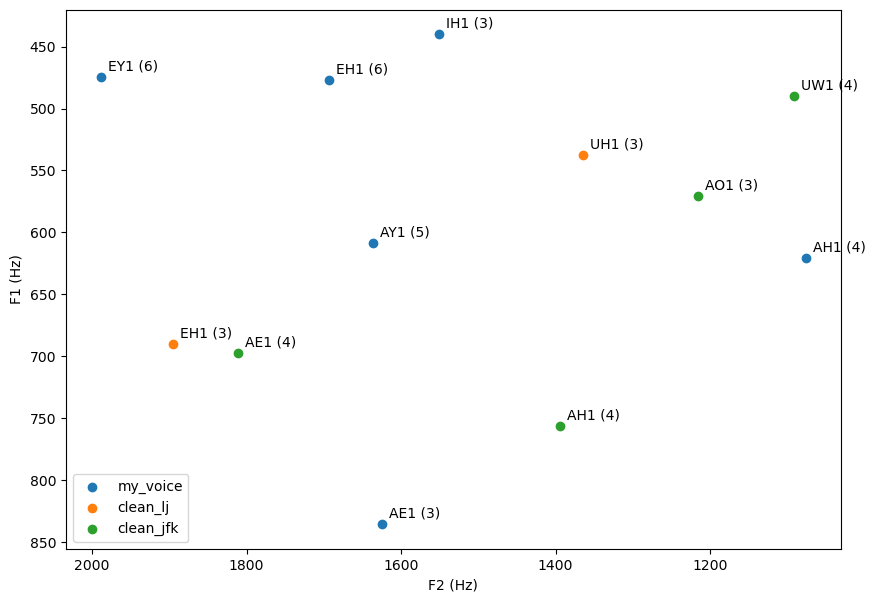

In [38]:
fig, ax = plt.subplots(figsize=(10, 7))
for speaker, stats in plot_results.items():
    ax.scatter(
        stats["F2"],
        stats["F1"],
        label=speaker
    )

    for label, row in stats.iterrows():
        ax.annotate(
            label + " (" + str(int(row["count"])) + ")",
            (row["F2"], row["F1"]),
            xytext=(5, 5),
            textcoords="offset points"
        )

ax.invert_xaxis()
ax.invert_yaxis()

ax.set_xlabel("F2 (Hz)")
ax.set_ylabel("F1 (Hz)")
ax.legend()
plt.show()

## Problem 2(c): Alignment of slowed speech

The last question connects this problem to the previous one. Your my_voice_slow recording is
the same speech as my_voice, stretched by PSOLA to 1.5 times its length, so a good aligner should
find every word 1.5 times as long. Divide the duration of each word in my_voice_slow by its
duration in my_voice, and report the median, minimum and maximum of these ratios along with
the four words with the most extreme ratios. Discuss what ratio you expected, whether the aligner
agrees, and what a deviation would tell you: is it more likely a flaw in PSOLA or in the alignment?

In [ ]:
my_voice_tg = parselmouth.read(f"{textgrid_dir}/my_voice.TextGrid")
my_voice_slower_tg = parselmouth.read(f"{textgrid_dir}/my_voice_slower.TextGrid")

my_voice_word_df = get_tier_df(my_voice_tg, 1)
my_voice_slower_word_df = get_tier_df(my_voice_slower_tg, 1)
assert my_voice_word_df['label'].equals(my_voice_slower_word_df['label']) # check if word labels are the same

In [ ]:
labels = my_voice_word_df['label'].values
duration_diff = np.array((my_voice_slower_word_df['duration'] / my_voice_word_df['duration']).values)
median_duration_diff, min_duration_diff, max_duration_diff = np.median(duration_diff), np.min(duration_diff), np.max(duration_diff)
print(f"Median duration diff: {median_duration_diff:.3f}, Min duration diff: {min_duration_diff:.3f}, Max duration diff: {max_duration_diff:.3f}")

argsort_duration_diff = np.argsort(duration_diff)
extreme_indices = argsort_duration_diff[[0, 1, -2, -1]]
for i in extreme_indices:
    print(f"Index: {i}, Label: {labels[i]}, Duration diff: {duration_diff[i]:.3f}")


Median duration diff: 1.476, Min duration diff: 1.333, Max duration diff: 2.000
Index: 1, Label: the, Duration diff: 1.333
Index: 49, Label: the, Duration diff: 1.333
Index: 20, Label: a, Duration diff: 1.833
Index: 34, Label: a, Duration diff: 2.000
